<a href="https://colab.research.google.com/github/Taheri1400/deep-learning-projects/blob/main/LSTM_music_generation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 align=center style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
تولید موسیقی با شبکه‌های عصبی بازگشتی (LSTM)
</font>
</h1>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
در این پروژه، هدف ما آموزش یک مدل یادگیری عمیق مبتنی بر شبکه‌های عصبی بازگشتی (LSTM) برای تولید موسیقی است. این پروژه به صورت مرحله‌به‌مرحله و با توضیحات ساده پیاده‌سازی شده تا برای افراد تازه‌وارد در حوزه یادگیری عمیق و شبکه‌های عصبی قابل فهم باشد. ما از یک فایل MIDI به عنوان ورودی استفاده می‌کنیم، نت‌ها و آکوردها را استخراج می‌کنیم، آن‌ها را به مدل LSTM آموزش می‌دهیم و در نهایت یک قطعه موسیقی جدید تولید می‌کنیم که به صورت فایل MIDI ذخیره می‌شود.
<br><b>هدف پروژه:</b> یادگیری چگونگی استفاده از LSTM برای مدل‌سازی دنباله‌های زمانی (مانند نت‌های موسیقی) و تولید خروجی‌های خلاقانه.
</font>
</p>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from music21 import converter, instrument, note, chord, stream
from keras.models import Sequential
from keras.layers import LSTM, Dropout, Dense, Activation
from keras.callbacks import ModelCheckpoint, EarlyStopping, CSVLogger
import random
import os

# تنظیم فونت فارسی برای matplotlib
plt.rcParams['font.family'] = 'Vazir'
plt.rcParams['font.size'] = 12
plt.rcParams['axes.unicode_minus'] = False

<h4 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
آماده‌سازی داده‌ها
</font>
</h4>
<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
در این بخش، داده‌های موسیقی از یک فایل MIDI استخراج می‌شوند. فایل MIDI شامل نت‌ها و آکوردهای موسیقی است که با استفاده از کتابخانه <code>music21</code> پردازش می‌شود. تابع <code>get_notes</code> نت‌ها و آکوردها را از فایل MIDI می‌خواند و به صورت رشته‌های متنی ذخیره می‌کند. اگر فایل MIDI شامل چندین ساز باشد، فقط نت‌های اولین ساز (پارت) استخراج می‌شوند. در غیر این صورت، تمام نت‌های موجود در فایل به صورت یکپارچه پردازش می‌شوند.
<br><b>مراحل:</b>
<ul>
<li>بارگذاری فایل MIDI با استفاده از <code>converter.parse</code>.</li>
<li>استخراج نت‌ها (به صورت رشته مانند 'C4') و آکوردها (به صورت اعداد normal order مانند '0.4.7').</li>
<li>ذخیره نت‌ها و آکوردها در یک لیست برای استفاده در مراحل بعدی.</li>
</ul>
</font>
</p>

In [ ]:
def get_notes():
    notes = []
    midi = converter.parse('original_metheny.mid')  # Replace with your dataset
    notes_to_parse = None
    try:
        s2 = instrument.partitionByInstrument(midi)
        notes_to_parse = s2.parts[0].recurse()
    except:
        notes_to_parse = midi.flat.notes

    for element in notes_to_parse:
        if isinstance(element, note.Note):
            notes.append(str(element.pitch))
        elif isinstance(element, chord.Chord):
            notes.append('.'.join(str(n) for n in element.normalOrder))
    return notes

<h4 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
بررسی داده‌های استخراج‌شده
</font>
</h4>
<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
پس از استخراج نت‌ها و آکوردها، تعداد کل نت‌ها و اندازه واژگان منحصربه‌فرد (تعداد نت‌ها و آکوردهای مختلف) را محاسبه می‌کنیم. این اطلاعات به ما کمک می‌کند تا ابعاد داده‌های ورودی و خروجی مدل را درک کنیم. واژگان منحصربه‌فرد بعداً برای تبدیل نت‌ها به اعداد و بالعکس استفاده می‌شود.
</font>
</p>

In [ ]:
notes = get_notes()
print(f"تعداد کل نت‌ها و آکوردها: {len(notes)}")

pitchnames = sorted(set(notes))
n_vocab = len(pitchnames)
print(f"اندازه واژگان منحصربه‌فرد: {n_vocab}")

تعداد کل نت‌ها و آکوردها: 647
اندازه واژگان منحصربه‌فرد: 120


<h4 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
آماده‌سازی دنباله‌های ورودی و خروجی
</font>
</h4>
<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
برای آموزش مدل LSTM، داده‌ها باید به صورت دنباله‌های ورودی و خروجی آماده شوند. هر دنباله ورودی شامل <code>sequence_length</code> نت متوالی است و خروجی متناظر، نت یا آکورد بعدی است. نت‌ها به اعداد تبدیل می‌شوند (با استفاده از دیکشنری <code>note_to_int</code>) و ورودی‌ها نرمال‌سازی می‌شوند تا مقادیر بین 0 و 1 داشته باشند. خروجی‌ها به صورت one-hot encoding کدگذاری می‌شوند تا مدل بتواند کلاس بعدی را پیش‌بینی کند.
<br><b>مراحل:</b>
<ul>
<li>تبدیل نت‌ها به اعداد با استفاده از دیکشنری.</li>
<li>ایجاد دنباله‌های ورودی (طول 100) و خروجی (نت بعدی).</li>
<li>نرمال‌سازی ورودی‌ها و تبدیل خروجی‌ها به one-hot encoding.</li>
</ul>
</font>
</p>

In [ ]:
note_to_int = {note: number for number, note in enumerate(pitchnames)}

sequence_length = 100
network_input = []
network_output = []

for i in range(len(notes) - sequence_length):
    seq_in = notes[i:i + sequence_length]
    seq_out = notes[i + sequence_length]
    network_input.append([note_to_int[ch] for ch in seq_in])
    network_output.append(note_to_int[seq_out])

n_patterns = len(network_input)
network_input = np.reshape(network_input, (n_patterns, sequence_length, 1))
network_input = network_input / float(n_vocab)
network_output = np.eye(n_vocab)[network_output]

print(f"تعداد الگوهای آموزشی: {n_patterns}")

تعداد الگوهای آموزشی: 547


<h4 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
تعریف مدل LSTM
</font>
</h4>
<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
در این بخش، مدل LSTM را با استفاده از کتابخانه Keras تعریف می‌کنیم. مدل شامل سه لایه LSTM با 512 واحد است که با لایه‌های Dropout برای جلوگیری از بیش‌برازش (overfitting) ترکیب شده‌اند. در نهایت، دو لایه Dense و یک لایه Activation (softmax) برای پیش‌بینی احتمال هر کلاس (نت یا آکورد) اضافه می‌شوند. مدل با تابع loss کاتگوریکال کراس‌انتropی و بهینه‌ساز Adam کامپایل می‌شود.
<br><b>ساختار مدل:</b>
<ul>
<li>سه لایه LSTM با 512 واحد و return_sequences برای لایه‌های اول و دوم.</li>
<li>لایه‌های Dropout با نرخ 0.3 برای کاهش بیش‌برازش.</li>
<li>لایه Dense با 256 واحد و سپس لایه خروجی با اندازه واژگان (n_vocab).</li>
</ul>
</font>
</p>

In [ ]:
model = Sequential()
model.add(LSTM(512, input_shape=(network_input.shape[1], network_input.shape[2]), return_sequences=True))
model.add(Dropout(0.3))
model.add(LSTM(512, return_sequences=True))
model.add(Dropout(0.3))
model.add(LSTM(512))
model.add(Dense(256))
model.add(Dropout(0.3))
model.add(Dense(n_vocab))
model.add(Activation('softmax'))
model.compile(loss='categorical_crossentropy', optimizer='adam')
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 100, 512)       │     1,052,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100, 512)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 100, 512)       │     2,099,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100, 512)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 512)            │     2,099,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 120)            │        30,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 120)            │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,413,240 (20.65 MB)

 Trainable params: 5,413,240 (20.65 MB)

 Non-trainable params: 0 (0.00 B)

<h4 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
آموزش مدل
</font>
</h4>
<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
مدل را با داده‌های آماده‌شده آموزش می‌دهیم. برای بهبود فرآیند آموزش، از callbackهایی مانند <code>ModelCheckpoint</code> برای ذخیره بهترین مدل و <code>EarlyStopping</code> برای جلوگیری از آموزش بیش از حد استفاده می‌کنیم. همچنین، تاریخچه آموزش در فایلی ذخیره می‌شود تا بتوانیم بعداً loss را بررسی کنیم.
<br><b>تنظیمات آموزش:</b>
<ul>
<li>تعداد epochها: 50</li>
<li>اندازه batch: 64</li>
<li>callbackها: ذخیره بهترین مدل، توقف زودهنگام، و ثبت تاریخچه.</li>
</ul>
</font>
</p>

In [ ]:
checkpoint = ModelCheckpoint('best_model.h5', monitor='loss', save_best_only=True, verbose=1)
early_stop = EarlyStopping(monitor='loss', patience=10, verbose=1)
csv_logger = CSVLogger('training_log.csv', append=True)

history = model.fit(network_input, network_output, epochs=50, batch_size=64,
                    callbacks=[checkpoint, early_stop, csv_logger], verbose=1)

Epoch 1/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - loss: 2.7626
Epoch 1: loss improved from None to 2.90412, saving model to best_model.h5



Epoch 1: finished saving model to best_model.h5
9/9 ━━━━━━━━━━━━━━━━━━━━ 56s 6s/step - loss: 2.9041
Epoch 2/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - loss: 2.8940
Epoch 2: loss improved from 2.90412 to 2.83988, saving model to best_model.h5



Epoch 2: finished saving model to best_model.h5
9/9 ━━━━━━━━━━━━━━━━━━━━ 57s 6s/step - loss: 2.8399
Epoch 3/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - loss: 2.6519
Epoch 3: loss improved from 2.83988 to 2.61170, saving model to best_model.h5



Epoch 3: finished saving model to best_model.h5
9/9 ━━━━━━━━━━━━━━━━━━━━ 56s 6s/step - loss: 2.6117
Epoch 4/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - loss: 2.3947
Epoch 4: loss improved from 2.61170 to 2.44609, saving model to best_model.h5



Epoch 4: finished saving model to best_model.h5
9/9 ━━━━━━━━━━━━━━━━━━━━ 82s 6s/step - loss: 2.4461
Epoch 5/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - loss: 2.2397
Epoch 5: loss improved from 2.44609 to 2.29442, saving model to best_model.h5


...


Epoch 44: finished saving model to best_model.h5
9/9 ━━━━━━━━━━━━━━━━━━━━ 56s 6s/step - loss: 0.6256
Epoch 45/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - loss: 0.5742
Epoch 45: loss improved from 0.62556 to 0.57679, saving model to best_model.h5



Epoch 45: finished saving model to best_model.h5
9/9 ━━━━━━━━━━━━━━━━━━━━ 57s 6s/step - loss: 0.5768
Epoch 46/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - loss: 0.5271
Epoch 46: loss improved from 0.57679 to 0.56026, saving model to best_model.h5



Epoch 46: finished saving model to best_model.h5
9/9 ━━━━━━━━━━━━━━━━━━━━ 57s 6s/step - loss: 0.5603
Epoch 47/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - loss: 0.5100
Epoch 47: loss improved from 0.56026 to 0.52128, saving model to best_model.h5



Epoch 47: finished saving model to best_model.h5
9/9 ━━━━━━━━━━━━━━━━━━━━ 55s 6s/step - loss: 0.5213
Epoch 48/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - loss: 0.5967
Epoch 48: loss did not improve from 0.52128
9/9 ━━━━━━━━━━━━━━━━━━━━ 82s 6s/step - loss: 0.6017
Epoch 49/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - loss: 0.4941
Epoch 49: loss improved from 0.52128 to 0.51264, saving model to best_model.h5



Epoch 49: finished saving model to best_model.h5
9/9 ━━━━━━━━━━━━━━━━━━━━ 83s 6s/step - loss: 0.5126
Epoch 50/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - loss: 0.5006
Epoch 50: loss did not improve from 0.51264
9/9 ━━━━━━━━━━━━━━━━━━━━ 81s 6s/step - loss: 0.5226


<h4 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
نمایش نمودار loss
</font>
</h4>
<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
برای ارزیابی عملکرد مدل، نمودار loss آموزش را رسم می‌کنیم. این نمودار نشان می‌دهد که مدل چگونه در طول زمان یاد می‌گیرد و آیا به همگرایی رسیده است یا خیر. نمودار در فایل <code>training_loss.png</code> ذخیره می‌شود.
</font>
</p>

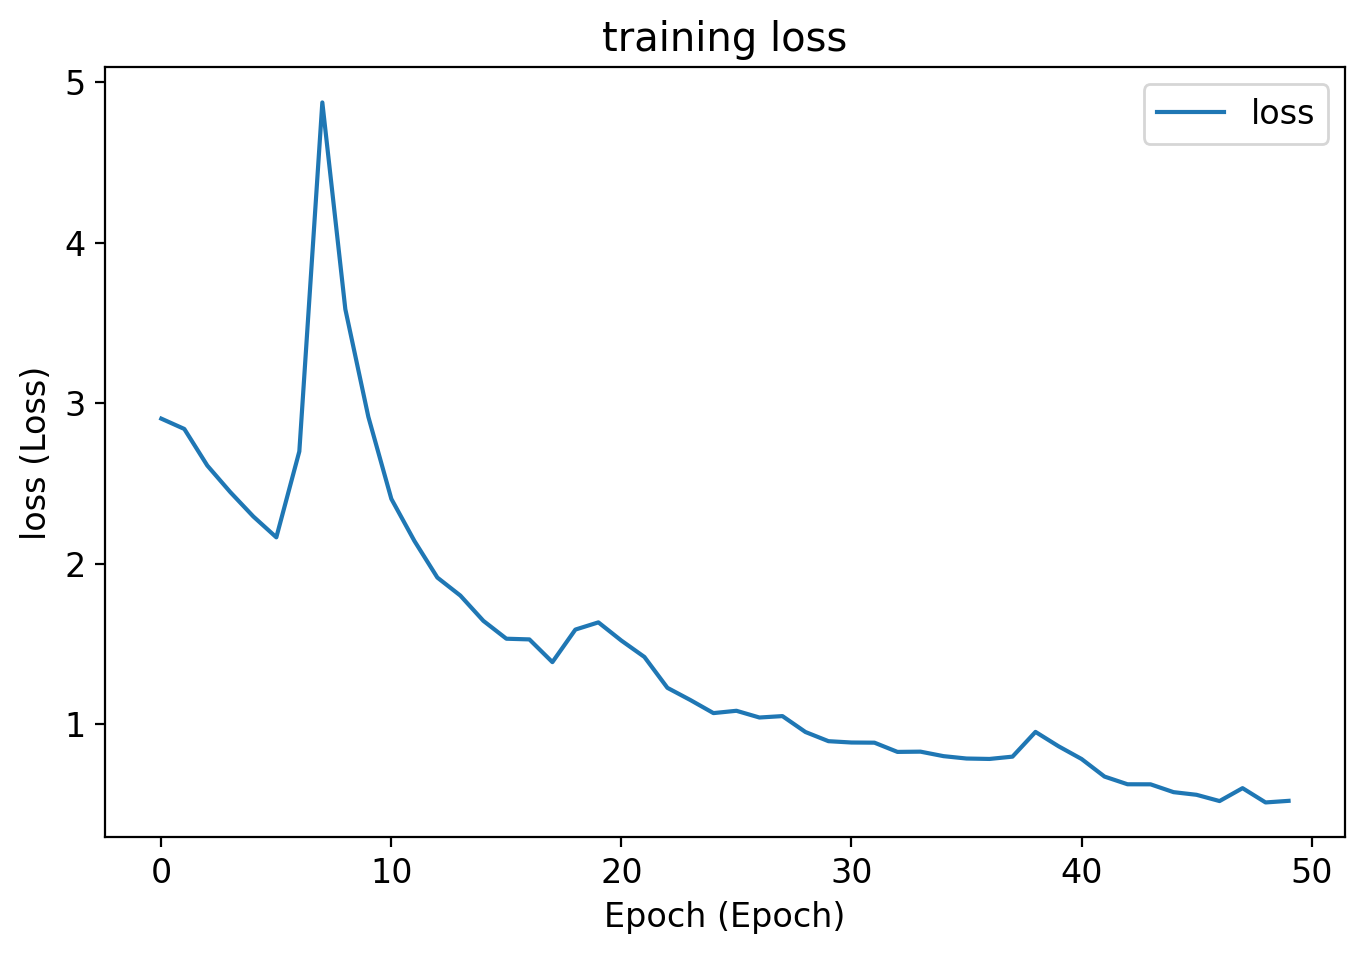

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='loss')
plt.xlabel('Epoch (Epoch)')
plt.ylabel('loss (Loss)')
plt.title('training loss')
plt.legend()
plt.savefig('training_loss.png')
plt.show()

<h4 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
تولید موسیقی
</font>
</h4>
<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
در این بخش، از مدل آموزش‌دیده برای تولید یک دنباله جدید از نت‌ها استفاده می‌کنیم. ابتدا یک دنباله تصادفی از داده‌های ورودی انتخاب می‌شود و سپس مدل به صورت بازگشتی نت بعدی را پیش‌بینی می‌کند. این فرآیند 200 بار تکرار می‌شود تا یک قطعه موسیقی جدید تولید شود. نت‌های پیش‌بینی‌شده در لیستی ذخیره می‌شوند.
</font>
</p>

In [ ]:
start = np.random.randint(0, len(network_input)-1)
pattern = network_input[start]

prediction_output = []
for note_index in range(200):
    prediction_input = np.reshape(pattern, (1, len(pattern), 1))
    prediction_input = prediction_input / float(n_vocab)
    prediction = model.predict(prediction_input, verbose=0)
    index = np.argmax(prediction)
    result = pitchnames[index]
    prediction_output.append(result)
    pattern = np.append(pattern, index)
    pattern = pattern[1:]

print("دنباله نت‌های تولیدشده:")
print(prediction_output[:50], "...")

دنباله نت‌های تولیدشده:
['11.2.4.7', '11.2.4.7', '11.2.4.7', '11.2.4.7', '11.2.4.7', '7.9.11.1.3', '7.9.11.1.3', '4.7.9.11.0', '4.7.9.11.0', '4.7.9.11.0', '4.7.9.11.0', '9.11.0.4', 'A4', 'A4', 'A4', 'A4', '11.0.4.7', '11.0.4.7', 'A1', 'A1', 'A1', 'A1', '4.7.9.11.0', 'G4', 'G4', 'G4', '11.0.4.7', '11.0.4.7', 'A1', 'A1', 'A1', '4.7.9.11.0', 'G4', 'G4', 'A4', 'G4', '0.4.7', '11.0.4.7', 'A1', '4.7.9.11.0', 'A1', '4.7.9.11.0', '9.11.0.4', 'G4', 'A4', 'B4', 'G4', '4.7.9.0', '4.7.9.11.0', '4.7.9.11.0'] ...


<h4 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
تبدیل نت‌ها به فایل MIDI
</font>
</h4>
<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
نت‌های تولیدشده به یک فایل MIDI تبدیل می‌شوند تا بتوان آن‌ها را شنید. هر نت یا آکورد به یک شیء <code>note.Note</code> یا <code>chord.Chord</code> تبدیل می‌شود و با استفاده از کتابخانه <code>music21</code> در یک جریان (stream) ذخیره می‌شود. فایل MIDI نهایی در <code>test_output.mid</code> ذخیره می‌شود.
<br><b>مراحل:</b>
<ul>
<li>تبدیل رشته‌های نت به اشیاء موسیقی (نت یا آکورد).</li>
<li>تنظیم ساز به پیانو و offset برای زمان‌بندی نت‌ها.</li>
<li>ذخیره جریان در فایل MIDI.</li>
</ul>
</font>
</p>

In [ ]:
offset = 0
output_notes = []
for pattern in prediction_output:
    if ('.' in pattern) or pattern.isdigit():
        notes_in_chord = pattern.split('.')
        notes_ = []
        for current_note in notes_in_chord:
            new_note = note.Note(int(current_note))
            new_note.storedInstrument = instrument.Piano()
            notes_.append(new_note)
        new_chord = chord.Chord(notes_)
        new_chord.offset = offset
        output_notes.append(new_chord)
    else:
        new_note = note.Note(pattern)
        new_note.offset = offset
        new_note.storedInstrument = instrument.Piano()
        output_notes.append(new_note)
    offset += 0.5

midi_stream = stream.Stream(output_notes)
output_file = 'test_output.mid'
midi_stream.write('midi', fp=output_file)

print(f"فایل MIDI با نام '{output_file}' با موفقیت تولید شد!")

فایل MIDI با نام 'test_output.mid' با موفقیت تولید شد!


<h4 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
پخش موسیقی تولیدشده
</font>
</h4>
<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
در این بخش، فایل MIDI تولیدشده با استفاده از کتابخانه <code>pygame</code> پخش می‌شود. اگر پخش خودکار ممکن نباشد، کاربر می‌تواند فایل را به صورت دستی در یک پخش‌کننده MIDI باز کند. این مرحله به مخاطب اجازه می‌دهد نتیجه کار مدل را به صورت شنیداری ارزیابی کند.
</font>
</p>

In [ ]:
try:
    import pygame
    pygame.init()
    pygame.mixer.init()
    pygame.mixer.music.load(output_file)
    pygame.mixer.music.play()
    print("در حال پخش موسیقی تولیدشده...")
except Exception as e:
    print("امکان پخش خودکار MIDI وجود ندارد. لطفاً فایل را به صورت دستی در یک پخش‌کننده MIDI باز کنید.")
    print("خطا:", e)

/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


pygame 2.6.1 (SDL 2.28.4, Python 3.13.16)
Hello from the pygame community. https://www.pygame.org/contribute.html
امکان پخش خودکار MIDI وجود ندارد. لطفاً فایل را به صورت دستی در یک پخش‌کننده MIDI باز کنید.
خطا: ALSA: Couldn't open audio device: No such file or directory
